In [1]:
import pandas as pd
import sqlite3
import numpy as np
import matplotlib.pyplot as plt

In [2]:
con = sqlite3.connect("PLStats.db")

In [3]:
stats = pd.read_excel("data/PremierLeagueStats.xlsx", sheet_name="Player Standard Stats", decimal=',')
stats = stats.rename(columns={"G-PK/90":"np_goals_per90", "npxG/90":"npxg_per90", "Minutes":"minutes", "Squad ID":"squad_id", "Player Fullname":"player_name", "Player ID":"player_id", "npxG":"npxg"})
stats.to_sql(name="stats", con=con, if_exists="replace")

positions = pd.read_excel("data/PremierLeagueStats.xlsx", sheet_name="Player Positions")
positions = positions.rename(columns={"Player ID":"player_id", "Player Position":"position"})
positions.to_sql(name="positions", con=con, if_exists="replace", index=True, index_label="pos_id")

squad = pd.read_excel("data/PremierLeagueStats.xlsx", sheet_name="Squad Standard Stats", decimal=',')
squad = squad.rename(columns={"Squad ID":"squad_id", "Squad":"squad_name"})
squad = squad[["squad_id", "squad_name"]]
squad.to_sql(name="squad", con=con, if_exists="replace", index=False)


20

In [4]:
pd.read_sql_query("SELECT * FROM stats", con=con)

,index,player_id,Player Name,Player Surname,Nation Code,squad_id,Age,Born,Matches Played,Starts,...,Assists/90,G+A/90,np_goals_per90,G+A-PK/90,xG/90,xAG/90,xG+xAG/90,npxg_per90,npxG+xAG/90,player_name
0,0,1,Brenden,Aaronson,USA,11,25-081,2000,20,14,...,0.22,0.51,0.29,0.51,0.21,0.20,0.41,0.21,0.41,Brenden Aaronson
1,1,2,Zach,Abbott,ENG,16,19-243,2006,1,0,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,Zach Abbott
2,2,3,Joshua,Acheampong,ENG,7,19-251,2006,8,6,...,0.00,0.19,0.19,0.19,0.12,0.01,0.13,0.12,0.13,Joshua Acheampong
3,3,4,Tyler,Adams,USA,3,26-331,1999,15,15,...,0.08,0.23,0.15,0.23,0.03,0.01,0.04,0.03,0.04,Tyler Adams
4,4,5,Tosin,Adarabioyo,ENG,7,28-109,1997,10,6,...,0.00,0.00,0.00,0.00,0.01,0.09,0.11,0.01,0.11,Tosin Adarabioyo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
488,488,489,Leny,Yoro,FRA,14,20-059,2005,21,12,...,0.00,0.00,0.00,0.00,0.05,0.00,0.06,0.05,0.06,Leny Yoro
489,489,490,Oleksandr,Zinchenko,UKR,16,29-027,1996,5,4,...,0.00,0.00,0.00,0.00,0.02,0.13,0.15,0.02,0.15,Oleksandr Zinchenko
490,490,491,Joshua,Zirkzee,NED,14,24-234,2001,14,4,...,0.18,0.55,0.37,0.55,0.36,0.17,0.52,0.36,0.52,Joshua Zirkzee
491,491,492,Martín,Zubimendi,ESP,1,26-343,1999,21,20,...,0.05,0.20,0.15,0.20,0.10,0.05,0.15,0.10,0.15,Martín Zubimendi


In [5]:
pd.read_sql_query("SELECT * FROM positions", con=con)

,pos_id,player_id,position
0,0,1,FW
1,1,1,MF
2,2,2,DF
3,3,3,DF
4,4,4,MF
...,...,...,...
612,612,490,DF
613,613,491,FW
614,614,491,MF
615,615,492,MF


In [6]:
pars = {"min_minutes":300, "position":"GK", "min_npxg":1, "min_same_pos_squad":3}

Bottom fifteen underperformers in terms of `non-penalty goals - non-penalty expected goals` overall. 

In [7]:
pd.read_sql_query("""
    SELECT player_name, np_goals_per90 - npxg_per90 AS g_xg_diff, minutes
    FROM stats
    WHERE minutes > :min_minutes
    ORDER BY g_xg_diff ASC LIMIT 15
""", con=con, params=pars)

,player_name,g_xg_diff,minutes
0,Justin Devenny,-0.32,513
1,David Brooks,-0.31,937
2,Andrey Santos,-0.29,520
3,Beto,-0.28,835
4,Anthony Gordon,-0.25,998
5,Liam Delap,-0.22,575
6,Jean-Philippe Mateta,-0.20,1730
7,Estêvão Willian,-0.20,610
8,Jhon Arias,-0.19,1048
9,Niclas Füllkrug,-0.19,409


Top fifteen overperformers in terms of `non-penalty goals - non-penalty expected goals` overall.

In [8]:
pd.read_sql_query("""
    SELECT player_name, np_goals_per90 - npxg_per90 AS g_xg_diff, minutes
    FROM stats
    WHERE minutes > :min_minutes
    ORDER BY g_xg_diff DESC LIMIT 15
""", con=con, params=pars)

,player_name,g_xg_diff,minutes
0,Eli Junior Kroupi,0.54,576
1,Mathys Tel,0.45,470
2,Mateus Mane,0.29,452
3,Emi Buendía,0.26,769
4,Samuel Chukwueze,0.22,398
5,Bruno Guimarães,0.20,1748
6,Antoine Semenyo,0.19,1798
7,Harry Wilson,0.19,1496
8,Zian Flemming,0.18,667
9,Morgan Rogers,0.18,1867


The same but using **CTE**.

In [9]:
pd.read_sql_query("""
    WITH xg_perform AS (
        SELECT player_name, np_goals_per90 - npxg_per90 AS g_xg_diff, minutes
        FROM stats
        WHERE minutes > :min_minutes)
    SELECT player_name, g_xg_diff, minutes FROM xg_perform
    ORDER BY g_xg_diff ASC LIMIT 15
""", con=con, params=pars)

,player_name,g_xg_diff,minutes
0,Justin Devenny,-0.32,513
1,David Brooks,-0.31,937
2,Andrey Santos,-0.29,520
3,Beto,-0.28,835
4,Anthony Gordon,-0.25,998
5,Liam Delap,-0.22,575
6,Jean-Philippe Mateta,-0.20,1730
7,Estêvão Willian,-0.20,610
8,Jhon Arias,-0.19,1048
9,Niclas Füllkrug,-0.19,409


Creating a ranking inside every squad using **CTE** and **window function**.

In [29]:
pd.read_sql_query("""
    WITH xg_perform AS (
        SELECT player_name, np_goals_per90 - npxg_per90 AS g_xg_diff, minutes, stats.squad_id AS squad_id, squad.squad_name AS squad_name
        FROM stats
        INNER JOIN squad ON squad.squad_id = stats.squad_id
        WHERE minutes > :min_minutes)
    SELECT player_name, g_xg_diff, minutes, squad_name,
           RANK() OVER (PARTITION BY squad_id ORDER BY g_xg_diff DESC) AS Ranking
    FROM xg_perform
""", con=con, params=pars)

,player_name,g_xg_diff,minutes,squad_name,Ranking
0,Eberechi Eze,0.17,923,Arsenal,1
1,Gabriel Magalhães,0.10,1266,Arsenal,2
2,Mikel Merino,0.09,940,Arsenal,3
3,Leandro Trossard,0.08,1131,Arsenal,4
4,Declan Rice,0.08,1696,Arsenal,5
...,...,...,...,...,...
367,Tolu Arokodare,-0.07,673,Wolves,18
368,Yerson Mosquera,-0.07,866,Wolves,18
369,Marshall Munetsi,-0.07,875,Wolves,18
370,Jørgen Strand Larsen,-0.08,1313,Wolves,21


Showing every squad's first place in `goals - xG` difference.

In [28]:
pd.read_sql_query("""
    WITH xg_perform AS (
        SELECT player_name, np_goals_per90 - npxg_per90 AS g_xg_diff, minutes, squad.squad_name, stats.squad_id AS squad_id
        FROM stats
        INNER JOIN squad ON squad.squad_id = stats.squad_id
        WHERE minutes > :min_minutes),
        rank_table AS (
            SELECT player_name, g_xg_diff, minutes, squad_name,
            RANK() OVER (PARTITION BY squad_id ORDER BY g_xg_diff DESC) AS ranking
            FROM xg_perform)
    SELECT player_name, g_xg_diff, minutes, squad_name FROM rank_table
        WHERE ranking = 1    
""", con=con, params=pars)

,player_name,g_xg_diff,minutes,squad_name
0,Eberechi Eze,0.17,923,Arsenal
1,Emi Buendía,0.26,769,Aston Villa
2,Eli Junior Kroupi,0.54,576,Bournemouth
3,Thiago,0.17,1752,Brentford
4,Danny Welbeck,0.17,1121,Brighton
5,Zian Flemming,0.18,667,Burnley
6,Moisés Caicedo,0.14,1342,Chelsea
7,Daniel Muñoz,0.08,1259,Crystal Palace
8,Kiernan Dewsbury-Hall,0.18,1257,Everton
9,Samuel Chukwueze,0.22,398,Fulham


Correlation between minutes played and the `goals - xG` difference. I wanted to see if a player plays more has a better chance to overperform his xG. Yet the correlation is very weak. Also this was another excercise for learning **CTE**.

In [12]:
pd.read_sql_query(sql = """WITH avg_min_g AS (
                                              SELECT np_goals_per90 - npxg_per90 AS g_xg_diff, minutes,
                                              AVG(np_goals_per90 - npxg_per90) OVER () AS avg_diff,
                                              AVG(minutes) OVER () AS avg_min 
                                              FROM stats
                                              WHERE minutes > :min_minutes), 
                                pwr_cov AS (
                                        SELECT POWER(g_xg_diff - avg_diff, 2) AS pwr_diff_xg,
                                        POWER(minutes - avg_min, 2) AS pwr_diff_min,
                                        (g_xg_diff - avg_diff)*(minutes - avg_min) AS cov
                                        FROM avg_min_g), 
                                elements AS (
                                         SELECT 1.0/(COUNT(*)-1)*SUM(pwr_diff_xg) AS var_xg, 
                                         1.0/(COUNT(*)-1)*SUM(pwr_diff_min) AS var_min,
                                         1.0/(COUNT(*)-1)*SUM(cov) AS cov FROM pwr_cov)
                            SELECT cov/(SQRT(var_min)*SQRT(var_xg)) AS corr_pearson 
                            FROM elements""", con = con, params=pars)

,corr_pearson
0,0.103409


Checked it against *Pandas* `.corr()` function. My calculations were correct.

In [13]:
stats["g_xg_diff"] = stats["np_goals_per90"] - stats["npxg_per90"]
stats[stats["minutes"] > 300][["minutes","g_xg_diff"]].corr(method="pearson")

,minutes,g_xg_diff
minutes,1.000000,0.103409
g_xg_diff,0.103409,1.000000


In [14]:
pd.read_sql_query("SELECT COUNT(*) FROM stats WHERE minutes > :min_minutes", con=con, params=pars)

,COUNT(*)
0,372


In [15]:
pd.read_sql_query("""SELECT * FROM positions WHERE position <> :position """, con=con, params=pars)

,pos_id,player_id,position
0,0,1,FW
1,1,1,MF
2,2,2,DF
3,3,3,DF
4,4,4,MF
...,...,...,...
582,612,490,DF
583,613,491,FW
584,614,491,MF
585,615,492,MF


First `JOIN` of two tables: `positions` and `stats`.

In [16]:
pd.read_sql_query("""SELECT player_name, np_goals_per90 - npxg_per90 AS g_xg_diff, minutes, squad_id, positions.position
                        FROM stats
                        INNER JOIN positions
                        ON stats.player_id = positions.player_id
                        WHERE minutes > :min_minutes AND positions.position <> :position
                        """, con=con, params=pars)

,player_name,g_xg_diff,minutes,squad_id,position
0,Brenden Aaronson,0.08,1245,11,FW
1,Brenden Aaronson,0.08,1245,11,MF
2,Joshua Acheampong,0.07,470,7,DF
3,Tyler Adams,0.12,1195,3,MF
4,Tosin Adarabioyo,-0.01,651,7,DF
...,...,...,...,...,...
431,Oleksandr Zinchenko,-0.02,353,16,DF
432,Joshua Zirkzee,0.01,490,14,FW
433,Joshua Zirkzee,0.01,490,14,MF
434,Martín Zubimendi,0.05,1769,1,MF


There are 92 players with two positions assigned. I will then have to delete the repetitions, because it will affect the rankings.

In [17]:
pd.read_sql_query("""SELECT COUNT(positions.player_id) - COUNT(DISTINCT positions.player_id)
                        FROM stats
                        INNER JOIN positions
                        ON stats.player_id = positions.player_id
                        WHERE minutes > :min_minutes AND positions.position <> :position
                        """, con=con, params=pars)

,COUNT(positions.player_id) - COUNT(DISTINCT positions.player_id)
0,92


This dataframe shows what is the distribution of `npxG`, so that I could assess how much of `npxG` I can cut to reduce the noise, but also have as much *club + position* divisions as possible.

In [18]:
filtered = pd.read_sql_query("""WITH players AS (
                                      SELECT stats.player_id AS player_id, player_name, positions.position AS position, 
                                      positions.pos_id, RANK() OVER (PARTITION BY positions.player_id ORDER BY pos_id) AS prim_pos, minutes, npxG
                                      FROM stats
                                      INNER JOIN positions
                                      ON stats.player_id = positions.player_id)
                                SELECT player_name, position, minutes, prim_pos, npxG
                                FROM players
                                WHERE minutes > :min_minutes AND position <> :position AND prim_pos = 1
""", con=con, params=pars)
filtered["npxG"].describe(percentiles = [.2,0.21,0.22,0.23,0.24,0.25,0.26,0.27,0.28,0.29, 0.5, 0.75])

count    344.000000
mean       1.509302
std        1.766856
min        0.000000
20%        0.300000
21%        0.300000
22%        0.300000
23%        0.389000
24%        0.400000
25%        0.400000
26%        0.400000
27%        0.400000
28%        0.500000
29%        0.500000
50%        0.900000
75%        1.900000
max       16.400000
Name: npxG, dtype: float64

I wanted to see how many groups are left after adding `WHERE npxg >= 1` filter. Before this it was **57** out of 60, now there are **33**.

In [19]:
pd.read_sql_query("""WITH players AS (
                                      SELECT stats.player_id as player_id, player_name, squad_id, positions.position AS position, 
                                      positions.pos_id, RANK() OVER (PARTITION BY positions.player_id ORDER BY pos_id) AS prim_pos, minutes, npxG
                                      FROM stats
                                      INNER JOIN positions
                                      ON stats.player_id = positions.player_id),
                    more_than_2 AS (SELECT COUNT(player_id) AS num_players, position, squad_id FROM players
                    WHERE minutes > :min_minutes AND position <> :position AND prim_pos = 1 AND npxG >= :min_npxg
                    GROUP BY squad_id, position)
                    SELECT position, squad_id, COUNT(num_players) OVER () FROM more_than_2
                    WHERE num_players > 2""", con=con, params=pars)

,position,squad_id,COUNT(num_players) OVER ()
0,DF,1,33
1,FW,1,33
2,MF,1,33
3,FW,2,33
4,FW,3,33
5,MF,3,33
6,FW,4,33
7,DF,5,33
8,FW,5,33
9,MF,5,33


This is DataFrame `g_xg_diff` I used for the scatter plot. It calculates the ranking within each club and position, so that it can answer the question for coach, who is the most consistent scorer we are currently having. Some of the positions in certain clubs don't have even two players with more than 300 minutes on field, so there is nothing to compare there.

In [20]:
g_xg_diff = pd.read_sql_query("""WITH players AS (
                                                  SELECT stats.player_id AS player_id, player_name, np_goals_per90 - npxg_per90 AS g_xg_diff, 
                                                  squad_id, positions.position AS position, positions.pos_id, 
                                                  RANK() OVER (PARTITION BY positions.player_id ORDER BY pos_id) AS prim_pos, 
                                                  minutes, npxg
                                                  FROM stats
                                                  INNER JOIN positions
                                                  ON stats.player_id = positions.player_id),
                                    more_than_2 AS (
                                                      SELECT player_name, g_xg_diff, position, squad_id, 
                                                      COUNT(player_id) OVER (PARTITION BY squad_id, position) AS same_pos_squad, 
                                                      minutes, prim_pos, npxg
                                                      FROM players
                                                      WHERE minutes > :min_minutes AND position <> :position AND prim_pos = 1)
                                    SELECT player_name, g_xg_diff, position, squad_id,
                                    RANK() OVER (PARTITION BY squad_id, position ORDER BY g_xg_diff DESC) AS squad_rank, npxg, minutes
                                    FROM more_than_2
                                    ORDER BY npxg DESC""", con=con, params=pars)

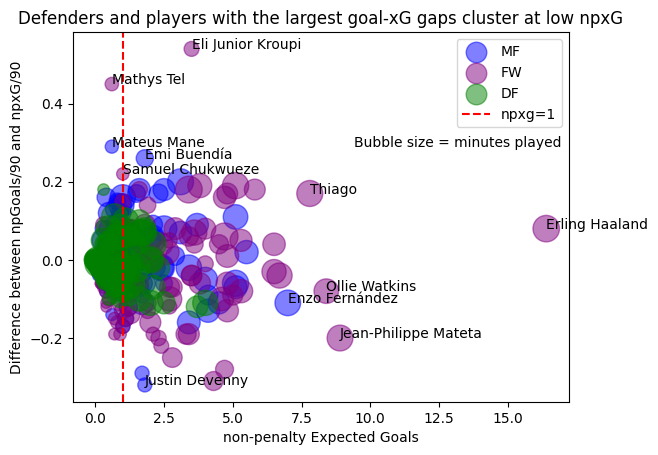

In [21]:
plt.scatter(x=g_xg_diff[g_xg_diff["position"] == "MF"]["npxg"], y=g_xg_diff[g_xg_diff["position"] == "MF"]["g_xg_diff"], c="blue", alpha=0.5, label="MF", 
            s=g_xg_diff[g_xg_diff["position"] == "MF"]["minutes"]/5)
plt.scatter(x=g_xg_diff[g_xg_diff["position"] == "FW"]["npxg"], y=g_xg_diff[g_xg_diff["position"] == "FW"]["g_xg_diff"], c="purple", alpha=0.5, label="FW", 
            s=g_xg_diff[g_xg_diff["position"] == "FW"]["minutes"]/5)
plt.scatter(x=g_xg_diff[g_xg_diff["position"] == "DF"]["npxg"], y=g_xg_diff[g_xg_diff["position"] == "DF"]["g_xg_diff"], c="green", alpha=0.5, label="DF", 
            s=g_xg_diff[g_xg_diff["position"] == "DF"]["minutes"]/5)
plt.text(x=9.4, y=0.29, s="Bubble size = minutes played")
plt.axvline(x=1, color='red', linestyle='--', label='npxg=1')
for _, row in g_xg_diff.iterrows():
    if (row["g_xg_diff"] > 0.2) | (row["g_xg_diff"] < -0.31) | (row["npxg"] >= 7):
        plt.annotate(row["player_name"], (row["npxg"], row["g_xg_diff"]), )
plt.title("Defenders and players with the largest goal-xG gaps cluster at low npxG")
plt.xlabel("non-penalty Expected Goals")
plt.ylabel("Difference between npGoals/90 and npxG/90")
plt.legend()

Both filters are not perfect and mainly arbitrary, because the data is limited (20 fixtures, so a little more than half a season). Like here, we see that Eli Junior Kroupi passes every filter I have, but still one can't tell if this is just a good run, or it proves his skills.

In [22]:
g_xg_diff[g_xg_diff["player_name"].isin(["Eli Junior Kroupi", "Erling Haaland"])]

,player_name,g_xg_diff,position,squad_id,squad_rank,npxg,minutes
0,Erling Haaland,0.08,FW,13,1,16.4,1821
40,Eli Junior Kroupi,0.54,FW,3,1,3.5,576


In [23]:
pd.read_sql_query("""SELECT COUNT(*) - COUNT(DISTINCT squad_id) FROM squad""", con=con)

,COUNT(*) - COUNT(DISTINCT squad_id)
0,0


In [24]:
club_pos_rank = pd.read_sql_query("""WITH players AS (
                                      SELECT stats.player_id AS player_id, player_name, np_goals_per90 - npxg_per90 AS g_xg_diff, 
                                      stats.squad_id as squad_id, positions.position AS position, positions.pos_id,
                                      RANK() OVER (PARTITION BY positions.player_id ORDER BY pos_id) AS prim_pos, minutes, npxg, squad.squad_name AS squad_name
                                      FROM stats
                                      INNER JOIN positions ON stats.player_id = positions.player_id
                                      INNER JOIN squad ON squad.squad_id = stats.squad_id),
                          more_than_2 AS (
                                          SELECT player_name, g_xg_diff, position, squad_id, 
                                          COUNT(player_id) OVER (PARTITION BY squad_id, position) AS same_pos_squad, 
                                          minutes, prim_pos, npxg, squad_name
                                          FROM players
                                          WHERE minutes > :min_minutes AND position <> :position AND position <> 'DF' AND prim_pos = 1 AND npxg >= :min_npxg)
                    SELECT player_name, g_xg_diff, position, squad_id,
                    RANK() OVER (PARTITION BY squad_id, position ORDER BY g_xg_diff DESC) AS squad_rank, npxg, minutes, squad_name
                    FROM more_than_2
                    WHERE same_pos_squad >= :min_same_pos_squad
                    ORDER BY npxg DESC""", con=con, params=pars)

The number of players with all the filters that are taken into the final ranking.

In [25]:
club_pos_rank.groupby(by="position").agg({"player_name":"count"})

,player_name
position,
FW,71
MF,46


In [26]:
club_pos_rank

,player_name,g_xg_diff,position,squad_id,squad_rank,npxg,minutes,squad_name
0,Ollie Watkins,-0.08,FW,2,4,8.4,1563,Aston Villa
1,Thiago,0.17,FW,4,1,7.8,1752,Brentford
2,Enzo Fernández,-0.11,MF,7,2,7.0,1701,Chelsea
3,Kevin Schade,-0.04,FW,4,3,6.7,1645,Brentford
4,João Pedro,-0.03,FW,7,2,6.5,1525,Chelsea
...,...,...,...,...,...,...,...,...
112,Sávio,-0.17,MF,13,5,1.0,541,Manchester City
113,Brennan Johnson,0.15,FW,18,2,1.0,610,Tottenham
114,Wilson Odobert,-0.13,FW,18,4,1.0,718,Tottenham
115,Mateus Fernandes,0.06,MF,19,1,1.0,1494,West Ham
